In [1]:
import tensorflow as tf
print(tf.__version__)


2.10.0


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [3]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

train_data = train_datagen.flow_from_directory(
    "C:/Users/ritik/Desktop/plant disese/PlantVillage",
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_data = train_datagen.flow_from_directory(
    "C:/Users/ritik/Desktop/plant disese/PlantVillage",
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.


In [4]:
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(train_data.num_classes, activation='softmax')
])

In [5]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [6]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
517/517 [==============================] - 336s 650ms/step - loss: 1.7822 - accuracy: 0.4285 - val_loss: 0.9947 - val_accuracy: 0.6742
Epoch 2/10
517/517 [==============================] - 201s 390ms/step - loss: 1.0958 - accuracy: 0.6425 - val_loss: 0.6743 - val_accuracy: 0.7751
Epoch 3/10
517/517 [==============================] - 197s 380ms/step - loss: 0.9150 - accuracy: 0.6972 - val_loss: 0.6344 - val_accuracy: 0.7952
Epoch 4/10
517/517 [==============================] - 259s 500ms/step - loss: 0.7996 - accuracy: 0.7346 - val_loss: 0.4752 - val_accuracy: 0.8440
Epoch 5/10
517/517 [==============================] - 121s 234ms/step - loss: 0.7299 - accuracy: 0.7575 - val_loss: 0.4871 - val_accuracy: 0.8285
Epoch 6/10
517/517 [==============================] - 120s 232ms/step - loss: 0.6579 - accuracy: 0.7768 - val_loss: 0.4223 - val_accuracy: 0.8569
Epoch 7/10
517/517 [==============================] - 121s 235ms/step - loss: 0.6035 - accuracy: 0.7983 - val_loss: 0.3684 -

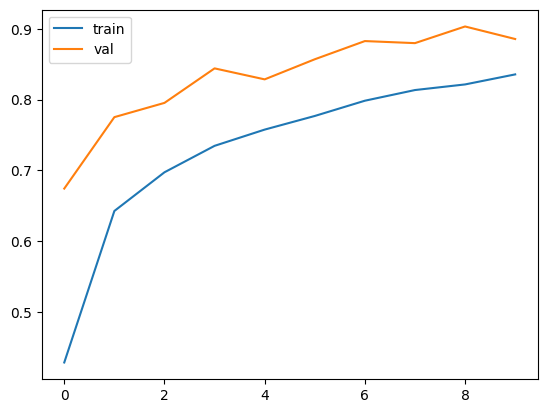

In [7]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.show()

In [8]:
model.save("plant_disease_model.h5")


In [10]:
from tensorflow.keras.preprocessing import image
import numpy as np

img = image.load_img(
    r"C:\Users\ritik\Downloads\archive (1)\PlantVillage\Potato___Late_blight\fc9b06c8-7c63-445d-9858-a5a0c7be719b___RS_LB 3273.JPG",
    target_size=(128,128)
)
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)
print(prediction)

1/1 [==============================] - 0s 210ms/step
[[9.1122917e-04 1.2790425e-04 2.2102742e-02 8.7543976e-01 4.5858300e-04
  7.4636249e-04 8.3231432e-03 8.9579031e-02 3.9549879e-05 9.3136850e-04
  4.9407256e-04 8.3276490e-04 1.2855918e-05 5.3867235e-09 6.4805675e-07]]


1/1 [==============================] - 0s 21ms/step


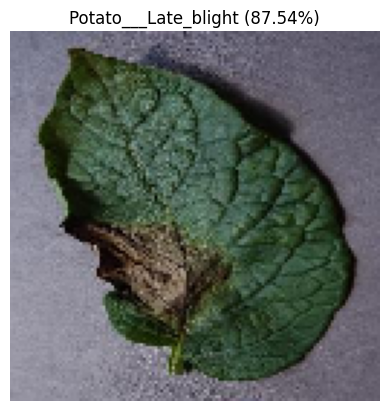

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing import image

# Load image
img_path = r"C:\Users\ritik\Downloads\archive (1)\PlantVillage\Potato___Late_blight\fc9b06c8-7c63-445d-9858-a5a0c7be719b___RS_LB 3273.JPG"

img = image.load_img(img_path, target_size=(128,128))
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)
pred_index = np.argmax(prediction)

# Class names
class_names = list(train_data.class_indices.keys())

predicted_class = class_names[pred_index]
confidence = prediction[0][pred_index] * 100

# Display image
plt.imshow(img)
plt.axis('off')
plt.title(f"{predicted_class} ({confidence:.2f}%)")
plt.show()